# Results Dashboard

This notebook aggregates experiment outputs from the five experiment scripts in [experiments](experiments).

Expected artifacts per run:
- results.json
- weights/*.npy

Default output root: outputs/

In [1]:
import matplotlib.pyplot as plt
import json
import numpy as np
# import h5py
from matplotlib.ticker import LogLocator
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, FixedLocator

plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
        "font.size": 8,
        "axes.linewidth": 0.6,
        "xtick.major.width": 0.4,
        "ytick.major.width": 0.4,
        "xtick.major.size": 2,
        "ytick.major.size": 2,
        "axes.labelsize": 8,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "figure.titlesize": 8,
    }
)

Trainable block type: product
Number of trainable parameters: 24
Non-Haar prior width: 0.35
Query direction: [1.0, 1.0]
Query layer weights: [1, 2]
x modes per coordinate: [-2, -1, 0, 1, 2]
ray modes: [-6, -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6]
ray grid size: 14
query-gate nonseparable weight (local max, nonlocal max): 0.000e+00, 0.750000
joint query spectrum (occupied modes, matches other series, out-of-support weight):  {'local': (49, True, '5.260e-17'), 'nonlocal': (49, True, '7.259e-17')}
fixed coefficient ranks:  {'nonlocal': 13, 'local': 13, 'local_narrow': 13}
maximum prior distances:  {'nonlocal': 0.10880746616898218, 'local': 0.0008301639908369143, 'local_narrow': 0.9969707339182445}
maximum class witness S(t):  {'nonlocal': 0.6948390374007014, 'local': 0.0, 'local_narrow': 0.0}
maximum mean effective Schmidt ranks:  {'nonlocal': 2.727249979632601, 'local': 1.0, 'local_narrow': 1.0}
Haar null noise ceiling: 0.0040
Case II separation (narrow peak / noise ceiling): 247.4


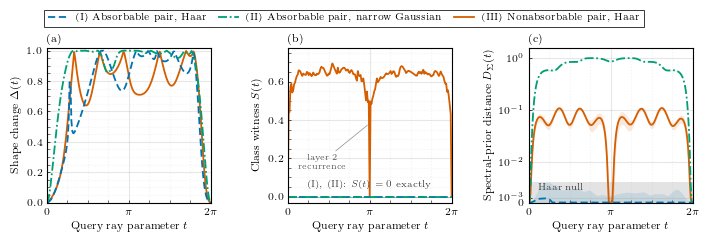

In [2]:
"""Query-conditioned inductive bias in a two-qubit reuploading circuit.

The circuit is a genuine data-reuploading ansatz in which the data
vector x and the query vector f are encoded in alternating layers, one
component per qubit in each:

    U(x, f; theta) = prod_{l=1}^{L} V_l E_f^(l)(f) W_l E_x(x),

    E_x(x)      = RZ_0(x_0) RZ_1(x_1),
    E_f^(l)(f)  = exp[-i s_l f_1 G_1 / 2] exp[-i s_l f_0 G_0 / 2].

Qubit q carries component q of both vectors, so the x layer and the f
layer have the same shape and the query is not concatenated into unused
encoding slots. The layer weights s_l = (1, 2) are common to both qubits.

The query is a genuine 2-vector. The abscissa of the figure is the ray
parameter t, with

    f(t) = t * QUERY_DIRECTION,   t in [0, 2 pi],

so the whole figure is a one-dimensional cut through the two-dimensional
query space, taken along a fixed direction.

Three series are compared, one per case of the trichotomy. They differ in
the query generator pair and in the parameter prior:

  "local"        Absorbable local pair G_q = X_q, Haar trainable blocks.
                 The query gate is a product of single-qubit unitaries at
                 every t, so it is absorbed into the adjacent product
                 block and H(f) = H(f'). Right invariance of Haar then
                 also gives Sigma(f) = Sigma(f'). Case I, and the
                 sampling null that calibrates panel (c).

  "local_narrow" The same absorbable pair, but Euler angles drawn from
                 untruncated zero-mean Gaussians. The support, hence the
                 reachable set and the hypothesis class, is unchanged, so
                 absorption still gives H(f) = H(f'). Right invariance is
                 lost, so Sigma(f) != Sigma(f'). Case II.

  "nonlocal"     Nonabsorbable swap-covariant pair G_0 = Y_0 Z_1,
                 G_1 = Z_0 Y_1, Haar trainable blocks. The query gate is
                 not a product unitary, so it cannot be absorbed; it
                 creates nonseparable dependence on (x_0, x_1) and moves
                 both the class and the prior. Case III.

The comparison is spectrum controlled. The two generator pairs are
isospectral,

    spec(d_0 X_0 + d_1 X_1) = spec(d_0 Y_0 Z_1 + d_1 Z_0 Y_1)

for every direction d, and within each pair the two generators commute.
The accessible query frequencies along the ray are therefore identical
for the absorbable and the nonabsorbable series, so panels (b) and (c)
cannot be explained by one series simply having access to more Fourier
content than another. validate_query_spectrum() checks this numerically
on the sampled ensemble rather than relying on the argument.

A common ZZ generator for both qubits would break this. It would make
G_0 = G_1, collapsing the query layer to exp[-i s_l (f_0 + f_1) ZZ / 2];
the circuit would then depend on f_0 + f_1 alone and the joint query
spectrum would shrink onto its diagonal. The swap-covariant pair keeps
the two query coordinates acting through distinct generators.

The figure reads as a two-bit classifier. Panel (a) is the naive test and
separates nothing. Panel (b) is the class bit and panel (c) is the prior
bit:

                      (b) class     (c) prior
      I   inert           0             0
      II  reweighting     0           nonzero
      III class change  nonzero       nonzero

The class bit is the maximum nonseparable weight

    S(f) = max_theta [ 1 - sigma_1^2 / sum_i sigma_i^2 ]

of the x-coefficient matrix A(theta, f). Every function in H(0) is
separable in (x_0, x_1) whenever the trainable blocks are products and
the query gate is a product, so S(f) > 0 exhibits a function at query f
that is not in H(0). Because S is a maximum, sampling can only
under-report it, which is the right direction for an existence claim; a
mean over theta would be a prior-weighted quantity and therefore the
wrong object for a statement about the class. For the absorbable series
with product blocks the state stays a product state, so the floor of S is
exactly zero rather than a sampling floor.

Set the environment variable

    TRAINABLE_BLOCKS=cnot

to insert a fixed CNOT after every local SU(2) layer. This is the more
expressive robustness variant, for which the experiment should be read as
a parameterization and prior comparison rather than a proof that the
global hypothesis classes differ. The absorbable pair remains absorbable
into the adjacent local factor for either block type, so the Case II
argument is unaffected by this switch.

Other environment variables:

    QUERY_DIRECTION=1,1   ray direction d in query space
    NARROW_SIGMA=0.35     width of the non-Haar prior
"""

import os

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D


# =====================================================================
# Configuration
# =====================================================================

NUMBER_OF_LAYERS = 2
QUERY_WEIGHTS = np.array([1, 2], dtype=int)

# The query is a 2-vector. The figure sweeps a ray f(t) = t * direction
# through query space, so the abscissa is the ray parameter t.
QUERY_DIRECTION = np.asarray(
    [
        float(component)
        for component in os.environ.get(
            "QUERY_DIRECTION", "1,1"
        ).split(",")
    ],
    dtype=float,
)
if QUERY_DIRECTION.size != 2:
    raise ValueError("QUERY_DIRECTION must have two components.")

# Four local SU(2) x SU(2) blocks: W_l,V_l for l=1,2.
# Each contains 2 x 3 Euler angles, giving 4 x 6 = 24 parameters.
NUMBER_OF_TRAINABLE_BLOCKS = 2 * NUMBER_OF_LAYERS
PARAMETERS_PER_BLOCK = 6
NUMBER_OF_PARAMETERS = (
    NUMBER_OF_TRAINABLE_BLOCKS * PARAMETERS_PER_BLOCK
)

GRID_SIZE = int(os.environ.get("GRID_SIZE", "8"))
# The ray axis carries higher frequencies than the x axes, because the
# layer generator d_0 G_0 + d_1 G_1 has eigenvalue spread |d_0| + |d_1|.
# Its grid is therefore sized separately, from the accessible mode set.
RAY_GRID_SIZE = int(os.environ.get("RAY_GRID_SIZE", "0"))
NUMBER_OF_ENSEMBLE_SAMPLES = int(
    os.environ.get("N_ENSEMBLE", "5000")
)
NUMBER_OF_SCHMIDT_SAMPLES = int(
    os.environ.get("N_SCHMIDT", "1000")
)
NUMBER_OF_QUERY_POINTS = int(
    os.environ.get("N_QUERY_POINTS", "181")
)
# Grid for the joint (f_0, f_1) spectrum check. It must resolve twice the
# largest accessible query frequency to detect out-of-support content.
QUERY_GRID_SIZE = int(os.environ.get("QUERY_GRID_SIZE", "24"))
NUMBER_OF_SPECTRUM_CHECK_SAMPLES = int(
    os.environ.get("N_SPECTRUM_CHECK", "4")
)
SPECTRUM_CHECK_SEED = 99
# A query-Fourier mode counts as occupied above this magnitude. Populated
# modes sit far above it and vanishing ones near machine epsilon, so the
# classification is insensitive to the exact threshold.
SPECTRUM_OCCUPATION_TOLERANCE = 1e-10
NUMBER_OF_JACKKNIFE_BLOCKS = int(
    os.environ.get("N_JACKKNIFE_BLOCKS", "10")
)

# Standard deviation of the non-Haar Euler-angle prior, in radians.
NARROW_SIGMA = float(os.environ.get("NARROW_SIGMA", "0.35"))

TRAINABLE_BLOCKS = os.environ.get(
    "TRAINABLE_BLOCKS", "product"
).lower()
if TRAINABLE_BLOCKS not in {"product", "cnot"}:
    raise ValueError(
        "TRAINABLE_BLOCKS must be either 'product' or 'cnot'."
    )

def latex_is_usable():
    """
    Report whether matplotlib's usetex backend can actually run here.

    A machine can carry a latex binary while lacking the base format and
    macros that usetex needs. Probing once avoids losing a completed
    ensemble to a rendering failure in the final savefig call.
    """
    import shutil
    import subprocess

    if shutil.which("latex") is None or shutil.which("dvipng") is None:
        return False
    try:
        completed = subprocess.run(
            ["kpsewhich", "latex.ltx"],
            capture_output=True,
            timeout=30,
            check=False,
        )
    except (OSError, subprocess.SubprocessError):
        return False
    return completed.returncode == 0 and bool(completed.stdout.strip())


# USE_TEX=1 requests usetex, USE_TEX=0 forces mathtext. A request is
# honoured only if the installation can serve it; otherwise the figure
# falls back to mathtext with the Computer Modern font set.
USE_TEX_REQUESTED = os.environ.get("USE_TEX", "1") == "1"
USE_TEX = USE_TEX_REQUESTED and latex_is_usable()
RANK_TOLERANCE = 1e-9

FIXED_PARAMETER_SEED = 5
NARROW_FIXED_PARAMETER_SEED = 7
ENSEMBLE_SEED = 1234
NARROW_ENSEMBLE_SEED = 4321

# Each series is a pair (query encoding, parameter distribution).
SERIES = ("nonlocal", "local", "local_narrow")
QUERY_TYPE_OF_SERIES = {
    "nonlocal": "nonlocal",
    "local": "local",
    "local_narrow": "local",
}
DISTRIBUTION_OF_SERIES = {
    "nonlocal": "haar",
    "local": "haar",
    "local_narrow": "narrow",
}
ABSORBABLE_SERIES = ("local", "local_narrow")
QUERY_TYPES = ("local", "nonlocal")


# =====================================================================
# Operators and elementary gates
# =====================================================================

I2 = np.eye(2, dtype=complex)
X = np.array([[0.0, 1.0], [1.0, 0.0]], dtype=complex)
Y = np.array([[0.0, -1.0j], [1.0j, 0.0]], dtype=complex)
Z = np.diag([1.0, -1.0]).astype(complex)


def kron(*operators):
    """Kronecker product of an arbitrary number of operators."""
    result = np.array([[1.0 + 0.0j]])
    for operator in operators:
        result = np.kron(result, operator)
    return result


X0 = kron(X, I2)
X1 = kron(I2, X)
Y0 = kron(Y, I2)
Y1 = kron(I2, Y)
Z0 = kron(Z, I2)
Z1 = kron(I2, Z)
ZZ = Z0 @ Z1

# Query generator pairs, one generator per qubit. Qubit q is driven by
# component q of the query vector.
#
#   local     G_q = X_q                  product gate, absorbable
#   nonlocal  G_0 = Y_0 Z_1, G_1 = Z_0 Y_1   entangling, not absorbable
#
# Within each pair the two generators commute, so the layer gate is
# unambiguous, and the two pairs are isospectral for every direction d,
# which is what makes the comparison spectrum controlled. A shared ZZ for
# both qubits would instead make G_0 = G_1 and collapse the joint query
# spectrum onto its diagonal.
QUERY_GENERATORS = {
    "local": (X0, X1),
    "nonlocal": (kron(Y, Z), kron(Z, Y)),
}

CNOT_01 = np.array(
    [
        [1.0, 0.0, 0.0, 0.0],
        [0.0, 1.0, 0.0, 0.0],
        [0.0, 0.0, 0.0, 1.0],
        [0.0, 0.0, 1.0, 0.0],
    ],
    dtype=complex,
)


def pauli_rotation(pauli, angle):
    r"""Return exp(-i angle pauli / 2)."""
    dimension = pauli.shape[0]
    return (
        np.cos(angle / 2.0) * np.eye(dimension, dtype=complex)
        - 1j * np.sin(angle / 2.0) * pauli
    )


def single_qubit_su2(euler_angles):
    r"""Euler parameterization RZ(alpha) RY(beta) RZ(gamma)."""
    alpha, beta, gamma = euler_angles
    return (
        pauli_rotation(Z, alpha)
        @ pauli_rotation(Y, beta)
        @ pauli_rotation(Z, gamma)
    )


def sample_haar_euler_parameters(rng):
    r"""Sample ZYZ Euler angles corresponding to Haar measure on SU(2)."""
    alpha = rng.uniform(0.0, 2.0 * np.pi)
    gamma = rng.uniform(0.0, 2.0 * np.pi)
    beta = np.arccos(rng.uniform(-1.0, 1.0))
    return np.array([alpha, beta, gamma])


def sample_narrow_euler_parameters(rng):
    r"""
    Sample ZYZ Euler angles from zero-mean Gaussians of width NARROW_SIGMA.

    The Gaussians are untruncated, so the angles have full support on R^3
    and the induced measure on SU(2) has full support even though it is
    strongly concentrated near the identity. The hypothesis class is
    therefore unchanged relative to the Haar case, while the induced
    distribution over unitaries is very far from Haar and in particular
    is not right invariant.
    """
    return rng.normal(0.0, NARROW_SIGMA, size=3)


PARAMETER_SAMPLERS = {
    "haar": sample_haar_euler_parameters,
    "narrow": sample_narrow_euler_parameters,
}


def sample_parameters(rng, distribution="haar"):
    """Sample the 24 Euler-angle parameters of the complete circuit."""
    sampler = PARAMETER_SAMPLERS[distribution]
    parameters = np.empty(
        (NUMBER_OF_TRAINABLE_BLOCKS, 2, 3), dtype=float
    )
    for block in range(NUMBER_OF_TRAINABLE_BLOCKS):
        for qubit in range(2):
            parameters[block, qubit] = sampler(rng)
    return parameters


def trainable_block(block_parameters, block_type):
    r"""Construct U^(0) tensor U^(1), optionally followed by CNOT."""
    local = kron(
        single_qubit_su2(block_parameters[0]),
        single_qubit_su2(block_parameters[1]),
    )
    if block_type == "product":
        return local
    if block_type == "cnot":
        # In circuit order, the local Euler rotations act first.
        return CNOT_01 @ local
    raise ValueError("Unknown trainable block type.")


def data_encoding(x):
    r"""E_x(x) = RZ(x_0) tensor RZ(x_1)."""
    return pauli_rotation(Z0, x[0]) @ pauli_rotation(Z1, x[1])


def query_encoding(query_vector, layer, query_type):
    r"""
    E_f^(l)(f) = exp[-i s_l f_1 G_1 / 2] exp[-i s_l f_0 G_0 / 2].

    The query is a 2-vector encoded one component per qubit, structurally
    identical to the data layer: qubit q is driven by component q through
    generator G_q. Both generators of a pair commute, so the order of the
    two factors does not matter.
    """
    if query_type not in QUERY_GENERATORS:
        raise ValueError(
            "query_type must be either 'local' or 'nonlocal'."
        )

    generator_0, generator_1 = QUERY_GENERATORS[query_type]
    weight = QUERY_WEIGHTS[layer]
    return pauli_rotation(
        generator_1, weight * query_vector[1]
    ) @ pauli_rotation(generator_0, weight * query_vector[0])


def query_vector_at(ray_parameter):
    """Point on the query ray f(t) = t * QUERY_DIRECTION."""
    return ray_parameter * QUERY_DIRECTION


# =====================================================================
# Circuit and Fourier coefficients
# =====================================================================

PLUS = np.array([1.0, 1.0], dtype=complex) / np.sqrt(2.0)
INITIAL_STATE = kron(PLUS, PLUS).reshape(-1)


def circuit_value(
    parameters,
    x,
    query_vector,
    query_type,
    block_type=TRAINABLE_BLOCKS,
):
    r"""
    Evaluate <Z_0 Z_1> for

        [E_x W_1 E_f V_1] [E_x W_2 E_f V_2],

    where the expression is written in circuit order from left to right.
    """
    blocks = [
        trainable_block(parameters[index], block_type)
        for index in range(NUMBER_OF_TRAINABLE_BLOCKS)
    ]

    total_unitary = np.eye(4, dtype=complex)

    for layer in range(NUMBER_OF_LAYERS):
        W_layer = blocks[2 * layer]
        V_layer = blocks[1 + 2 * layer]
        total_unitary = (
            V_layer
            @ query_encoding(query_vector, layer, query_type)
            @ W_layer
            @ data_encoding(x)
            @ total_unitary
        )

    state = total_unitary @ INITIAL_STATE
    expectation = state.conj() @ ZZ @ state

    if abs(expectation.imag) > 1e-10:
        raise RuntimeError(
            "Expectation value has an unexpectedly large imaginary part."
        )
    return expectation.real


def accessible_ray_modes():
    r"""
    Frequencies of t accessible to the circuit along f(t) = t * d.

    Layer l contributes exp[-i s_l t (d_0 G_0 + d_1 G_1) / 2] because the
    two generators of a pair commute, so its frequencies are the halved
    eigenvalue differences of that generator, scaled by s_l. The full set
    is the Minkowski sum over layers. Both generator pairs are isospectral
    for every d, so this set is the same for the absorbable and the
    nonabsorbable series.
    """
    per_query_type = {}
    for query_type in QUERY_TYPES:
        generator_0, generator_1 = QUERY_GENERATORS[query_type]
        layer_generator = (
            QUERY_DIRECTION[0] * generator_0
            + QUERY_DIRECTION[1] * generator_1
        )
        eigenvalues = np.linalg.eigvalsh(layer_generator)
        differences = {
            (left - right) / 2.0
            for left in eigenvalues
            for right in eigenvalues
        }

        modes = {0.0}
        for weight in QUERY_WEIGHTS:
            layer_modes = {
                weight * difference for difference in differences
            }
            modes = {
                left + right
                for left in modes
                for right in layer_modes
            }

        if any(
            abs(mode - round(mode)) > 1e-9 for mode in modes
        ):
            raise ValueError(
                "QUERY_DIRECTION must give integer ray frequencies so "
                "that the ray spectrum lies on the Fourier grid; use "
                "integer components."
            )
        per_query_type[query_type] = frozenset(
            round(mode) for mode in modes
        )

    # Isospectral generator pairs must predict the same ray spectrum.
    # This is the analytic half of the spectrum-controlled claim that
    # validate_query_spectrum() then confirms numerically.
    distinct = set(per_query_type.values())
    if len(distinct) != 1:
        raise RuntimeError(
            "The query types predict different ray spectra: "
            + ", ".join(
                f"{query_type} has {len(modes)} modes"
                for query_type, modes in per_query_type.items()
            )
        )
    return np.asarray(sorted(distinct.pop()), dtype=int)


RAY_MODES = accessible_ray_modes()
MAXIMUM_RAY_FREQUENCY = int(np.max(RAY_MODES))
if RAY_GRID_SIZE == 0:
    # Twice the largest frequency resolves the spectrum; one more point
    # leaves a mode that must stay empty, which turns aliasing into a
    # detectable failure rather than a silent wrap-around.
    RAY_GRID_SIZE = 2 * MAXIMUM_RAY_FREQUENCY + 2
if RAY_GRID_SIZE <= 2 * MAXIMUM_RAY_FREQUENCY:
    raise ValueError(
        "RAY_GRID_SIZE must exceed twice the largest ray frequency "
        f"({MAXIMUM_RAY_FREQUENCY})."
    )


def precomputed_operators(block_type):
    """Precompute input-independent objects used on the Fourier grid."""
    scalar_grid = 2.0 * np.pi * np.arange(GRID_SIZE) / GRID_SIZE
    ray_grid = (
        2.0 * np.pi * np.arange(RAY_GRID_SIZE) / RAY_GRID_SIZE
    )
    data_encodings = [
        [data_encoding(np.array([x0, x1])) for x1 in scalar_grid]
        for x0 in scalar_grid
    ]
    query_encodings = {
        query_type: [
            [
                query_encoding(
                    query_vector_at(ray_parameter), layer, query_type
                )
                for ray_parameter in ray_grid
            ]
            for layer in range(NUMBER_OF_LAYERS)
        ]
        for query_type in QUERY_TYPES
    }
    return scalar_grid, ray_grid, data_encodings, query_encodings


(
    SCALAR_GRID,
    RAY_GRID,
    DATA_ENCODINGS,
    QUERY_ENCODINGS,
) = precomputed_operators(TRAINABLE_BLOCKS)


def coefficient_tensor(parameters, query_type, block_type=TRAINABLE_BLOCKS):
    r"""Return C[omega_x0, omega_x1, omega_f] from a three-dimensional FFT."""
    blocks = [
        trainable_block(parameters[index], block_type)
        for index in range(NUMBER_OF_TRAINABLE_BLOCKS)
    ]
    values = np.empty(
        (GRID_SIZE, GRID_SIZE, RAY_GRID_SIZE), dtype=float
    )

    for ix0 in range(GRID_SIZE):
        for ix1 in range(GRID_SIZE):
            Ex = DATA_ENCODINGS[ix0][ix1]

            for jf in range(RAY_GRID_SIZE):
                total_unitary = np.eye(4, dtype=complex)

                for layer in range(NUMBER_OF_LAYERS):
                    W_layer = blocks[2 * layer]
                    V_layer = blocks[1 + 2 * layer]
                    total_unitary = (
                        V_layer
                        @ QUERY_ENCODINGS[query_type][layer][jf]
                        @ W_layer
                        @ Ex
                        @ total_unitary
                    )

                state = total_unitary @ INITIAL_STATE
                expectation = state.conj() @ ZZ @ state
                values[ix0, ix1, jf] = expectation.real

    full_coefficients = np.fft.fftshift(
        np.fft.fftn(values)
        / (GRID_SIZE * GRID_SIZE * RAY_GRID_SIZE)
    )
    x_full_modes = np.fft.fftshift(
        np.fft.fftfreq(GRID_SIZE, d=1.0 / GRID_SIZE)
    ).astype(int)
    ray_full_modes = np.fft.fftshift(
        np.fft.fftfreq(RAY_GRID_SIZE, d=1.0 / RAY_GRID_SIZE)
    ).astype(int)

    x_keep = np.abs(x_full_modes) <= NUMBER_OF_LAYERS
    f_keep = np.abs(ray_full_modes) <= MAXIMUM_RAY_FREQUENCY

    # Weight outside the predicted band would mean the ray grid is
    # aliasing and the retained coefficients are contaminated.
    if np.any(~f_keep):
        outside = float(
            np.max(np.abs(full_coefficients[..., ~f_keep]))
        )
        if outside > 1e-10:
            raise RuntimeError(
                "Ray-Fourier weight appeared outside the predicted "
                f"band (max {outside:.3e}); RAY_GRID_SIZE is too small."
            )

    x_indices = np.flatnonzero(x_keep)
    f_indices = np.flatnonzero(f_keep)
    coefficients = full_coefficients[np.ix_(
        x_indices, x_indices, f_indices
    )]

    return (
        coefficients,
        x_full_modes[x_keep],
        ray_full_modes[f_keep],
    )


def coefficient_matrix_at_query(C, query_modes, query_value):
    r"""Return A(f), indexed by the x_0 and x_1 Fourier modes."""
    phases = np.exp(1j * query_modes * query_value)
    return np.einsum("ijk,k->ij", C, phases)


def coefficient_rank(C, relative_tolerance=RANK_TOLERANCE):
    """Rank of C grouped as all x modes against the query modes."""
    matrix = C.reshape(-1, C.shape[-1])
    singular_values = np.linalg.svd(matrix, compute_uv=False)
    return int(
        np.count_nonzero(
            singular_values
            > relative_tolerance * singular_values[0]
        )
    )


# =====================================================================
# Diagnostics
# =====================================================================

# Abscissa of the figure: the ray parameter t in f(t) = t * direction.
QUERY_VALUES = np.linspace(
    0.0, 2.0 * np.pi, NUMBER_OF_QUERY_POINTS
)


def fixed_parameter_shape_change(C, query_modes):
    r"""Delta(f) relative to f=0 for one fixed parameter vector."""
    reference = coefficient_matrix_at_query(
        C, query_modes, 0.0
    ).reshape(-1)
    reference_norm = np.linalg.norm(reference)

    changes = []
    for query_value in QUERY_VALUES:
        vector = coefficient_matrix_at_query(
            C, query_modes, query_value
        ).reshape(-1)
        similarity = np.abs(np.vdot(vector, reference)) / (
            np.linalg.norm(vector) * reference_norm
        )
        changes.append(1.0 - np.clip(similarity, 0.0, 1.0))

    changes = np.asarray(changes)
    changes[np.abs(changes) < 1e-12] = 0.0
    return changes


def normalized_matrix_distance(matrix, reference):
    r"""One minus normalized Frobenius alignment."""
    alignment = np.vdot(matrix, reference).real / (
        np.linalg.norm(matrix) * np.linalg.norm(reference)
    )
    return 1.0 - np.clip(alignment, 0.0, 1.0)


def coefficient_vectors_at_query(
    coefficient_samples,
    query_modes,
    query_value,
):
    """Evaluate all sampled x-coefficient vectors at one query value."""
    phases = np.exp(1j * query_modes * query_value)
    matrices = np.einsum(
        "nijk,k->nij", coefficient_samples, phases
    )
    return matrices.reshape(len(coefficient_samples), -1)


def prior_statistics(coefficient_samples, query_modes):
    r"""
    Estimate the spectral second moment

        Sigma_f = E_theta[a(theta,f) a(theta,f)^dagger]

    and its distance from Sigma_0. The distance is jackknife-bias
    corrected, with a jackknife standard error. Also return normalized
    Fourier power and the full-sample second-moment matrices.
    """
    number_of_samples = len(coefficient_samples)
    number_of_blocks = min(
        NUMBER_OF_JACKKNIFE_BLOCKS, number_of_samples
    )
    blocks = np.array_split(
        np.arange(number_of_samples), number_of_blocks
    )

    reference_vectors = coefficient_vectors_at_query(
        coefficient_samples, query_modes, 0.0
    )
    reference_sum = reference_vectors.conj().T @ reference_vectors
    reference = reference_sum / number_of_samples
    reference_block_sums = [
        reference_vectors[index].conj().T
        @ reference_vectors[index]
        for index in blocks
    ]

    prior_matrices = []
    normalized_powers = []
    raw_distances = []
    corrected_distances = []
    standard_errors = []

    for query_value in QUERY_VALUES:
        vectors = coefficient_vectors_at_query(
            coefficient_samples, query_modes, query_value
        )
        sigma_sum = vectors.conj().T @ vectors
        sigma = sigma_sum / number_of_samples
        prior_matrices.append(sigma)

        power = np.real(np.diag(sigma))
        normalized_powers.append(power / np.sum(power))

        raw_distance = normalized_matrix_distance(sigma, reference)
        raw_distances.append(raw_distance)

        leave_one_block_out = []
        for index, reference_block_sum in zip(
            blocks, reference_block_sums
        ):
            retained = number_of_samples - len(index)
            sigma_block_sum = (
                vectors[index].conj().T @ vectors[index]
            )
            sigma_loo = (sigma_sum - sigma_block_sum) / retained
            reference_loo = (
                reference_sum - reference_block_sum
            ) / retained
            leave_one_block_out.append(
                normalized_matrix_distance(
                    sigma_loo, reference_loo
                )
            )

        leave_one_block_out = np.asarray(leave_one_block_out)
        jackknife_mean = np.mean(leave_one_block_out)
        corrected = (
            number_of_blocks * raw_distance
            - (number_of_blocks - 1) * jackknife_mean
        )
        corrected_distances.append(max(0.0, corrected))
        standard_errors.append(
            np.sqrt(
                (number_of_blocks - 1)
                / number_of_blocks
                * np.sum(
                    (leave_one_block_out - jackknife_mean) ** 2
                )
            )
        )

    return (
        np.asarray(corrected_distances),
        np.asarray(standard_errors),
        np.asarray(raw_distances),
        np.asarray(normalized_powers),
        prior_matrices,
    )


def separability_measures(matrix, zero_tolerance=1e-15):
    r"""
    Return (nonseparable weight, entropy effective rank) of A(theta, f).

    Both follow from the same singular values. The nonseparable weight
    1 - sigma_1^2 / sum_i sigma_i^2 vanishes exactly for a rank-one, that
    is coordinate-separable, coefficient matrix.
    """
    singular_values = np.linalg.svd(matrix, compute_uv=False)
    weights = singular_values**2
    total = np.sum(weights)
    if total <= zero_tolerance:
        return 0.0, 0.0

    weights = weights / total
    nonseparable = float(1.0 - weights[0])

    retained = weights[weights > zero_tolerance]
    effective_rank = float(
        np.exp(-np.sum(retained * np.log(retained)))
    )
    return nonseparable, effective_rank


def separability_statistics(coefficient_samples, query_modes):
    r"""
    Class witness and companion diagnostics over the parameter samples.

    Returns the maximum nonseparable weight S(f), which is the class
    witness plotted in panel (b), together with the mean nonseparable
    weight and the mean effective Schmidt rank. The latter two are
    prior weighted and are reported only as context.
    """
    number_used = min(
        NUMBER_OF_SCHMIDT_SAMPLES, len(coefficient_samples)
    )
    selected = coefficient_samples[:number_used]

    maximum_weights = []
    mean_weights = []
    mean_ranks = []
    for query_value in QUERY_VALUES:
        measures = np.asarray([
            separability_measures(
                coefficient_matrix_at_query(
                    C, query_modes, query_value
                )
            )
            for C in selected
        ])
        maximum_weights.append(np.max(measures[:, 0]))
        mean_weights.append(np.mean(measures[:, 0]))
        mean_ranks.append(np.mean(measures[:, 1]))

    return (
        np.asarray(maximum_weights),
        np.asarray(mean_weights),
        np.asarray(mean_ranks),
    )


# =====================================================================
# Structural validation of the encoding
# =====================================================================

# A generic data point. The query spectrum must not depend on it.
SPECTRUM_CHECK_DATA_POINT = np.array([0.37, 1.13])


def operator_nonseparable_weight(gate):
    r"""
    Operator-Schmidt nonseparable weight of a two-qubit gate.

    Zero exactly for a product unitary A tensor B, which is exactly the
    condition under which the gate is absorbed into product trainable
    blocks. Positive values certify that no such absorption exists. This
    is the right test now that the query layer acts on both qubits; a
    single-qubit-gate check no longer applies.
    """
    reshuffled = (
        gate.reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(4, 4)
    )
    singular_values = np.linalg.svd(reshuffled, compute_uv=False)
    weights = singular_values**2
    return float(1.0 - weights[0] / np.sum(weights))


def validate_absorbability():
    """
    Confirm the absorbable query gate is a product and the other is not.

    Checked on the ray, at every layer, over the plotted abscissa.
    """
    weights = {query_type: [] for query_type in QUERY_TYPES}
    for query_type in QUERY_TYPES:
        for ray_parameter in QUERY_VALUES:
            for layer in range(NUMBER_OF_LAYERS):
                weights[query_type].append(
                    operator_nonseparable_weight(
                        query_encoding(
                            query_vector_at(ray_parameter),
                            layer,
                            query_type,
                        )
                    )
                )

    local_maximum = float(np.max(weights["local"]))
    nonlocal_maximum = float(np.max(weights["nonlocal"]))
    if local_maximum > 1e-12:
        raise RuntimeError(
            "The local query gate is not a product unitary "
            f"(nonseparable weight {local_maximum:.3e}); the "
            "absorption argument for Cases I and II fails."
        )
    if nonlocal_maximum <= 0.05:
        raise RuntimeError(
            "The nonlocal query gate is nearly a product unitary "
            f"(maximum nonseparable weight {nonlocal_maximum:.3e}); "
            "it would be effectively absorbable."
        )
    return {
        "local_maximum": local_maximum,
        "nonlocal_maximum": nonlocal_maximum,
    }


def joint_query_spectrum(parameters, query_type, block_type):
    r"""
    Joint query-Fourier coefficients C[omega_f0, omega_f1].

    The data vector and the parameters are held fixed and the circuit is
    evaluated on a QUERY_GRID_SIZE^2 grid in (f_0, f_1). This is the
    two-dimensional object behind the one-dimensional ray cut, and it is
    what must agree between the absorbable and nonabsorbable series for
    the comparison to be spectrum controlled.
    """
    blocks = [
        trainable_block(parameters[index], block_type)
        for index in range(NUMBER_OF_TRAINABLE_BLOCKS)
    ]
    encoding = data_encoding(SPECTRUM_CHECK_DATA_POINT)
    grid = (
        2.0 * np.pi * np.arange(QUERY_GRID_SIZE) / QUERY_GRID_SIZE
    )

    query_gates = np.asarray([
        [
            query_encoding(np.array([f0, f1]), layer, query_type)
            for f0 in grid
            for f1 in grid
        ]
        for layer in range(NUMBER_OF_LAYERS)
    ])

    states = np.broadcast_to(
        INITIAL_STATE,
        (QUERY_GRID_SIZE**2, INITIAL_STATE.size),
    ).copy()

    for layer in range(NUMBER_OF_LAYERS):
        W_layer = blocks[2 * layer]
        V_layer = blocks[1 + 2 * layer]
        states = np.einsum("ij,fj->fi", encoding, states, optimize=True)
        states = np.einsum("ij,fj->fi", W_layer, states, optimize=True)
        states = np.einsum(
            "fij,fj->fi", query_gates[layer], states, optimize=True
        )
        states = np.einsum("ij,fj->fi", V_layer, states, optimize=True)

    expectations = np.einsum(
        "fi,ij,fj->f", states.conj(), ZZ, states, optimize=True
    )
    values = expectations.real.reshape(
        QUERY_GRID_SIZE, QUERY_GRID_SIZE
    )
    return np.fft.fftshift(
        np.fft.fft2(values) / QUERY_GRID_SIZE**2
    )


def validate_query_spectrum(block_type=TRAINABLE_BLOCKS):
    r"""
    Verify that the two series have the same joint query spectrum.

    The occupied mode set is collected as a maximum over Haar parameter
    samples for each query type and the two sets are compared. Equality
    means panels (b) and (c) cannot be attributed to one series reaching
    Fourier content the other cannot reach. Containment in the predicted
    band is checked at the same time.
    """
    modes = np.fft.fftshift(
        np.fft.fftfreq(QUERY_GRID_SIZE, d=1.0 / QUERY_GRID_SIZE)
    ).astype(int)
    per_coordinate_maximum = int(np.sum(QUERY_WEIGHTS))
    inside = np.abs(modes) <= per_coordinate_maximum
    inside_mask = np.outer(inside, inside)
    mode_grid = np.stack(
        np.meshgrid(modes, modes, indexing="ij"), axis=-1
    )

    rng = np.random.default_rng(SPECTRUM_CHECK_SEED)
    parameter_samples = [
        sample_parameters(rng, "haar")
        for _ in range(NUMBER_OF_SPECTRUM_CHECK_SAMPLES)
    ]

    supports = {}
    report = {}
    for query_type in QUERY_TYPES:
        magnitudes = np.zeros_like(inside_mask, dtype=float)
        for parameters in parameter_samples:
            np.maximum(
                magnitudes,
                np.abs(
                    joint_query_spectrum(
                        parameters, query_type, block_type
                    )
                ),
                out=magnitudes,
            )

        leakage = float(np.max(magnitudes[~inside_mask]))
        if leakage > 1e-10:
            raise RuntimeError(
                f"The {query_type} query leaks Fourier weight outside "
                f"the predicted support (max {leakage:.3e})."
            )

        occupied = magnitudes > SPECTRUM_OCCUPATION_TOLERANCE
        supports[query_type] = frozenset(
            map(tuple, mode_grid[occupied].tolist())
        )
        report[query_type] = {
            "out_of_support_weight": leakage,
            "support_size": int(occupied.sum()),
        }

    difference = supports["local"] ^ supports["nonlocal"]
    identical = not difference
    for query_type in QUERY_TYPES:
        report[query_type]["support_matches_other"] = identical
    if not identical:
        message = (
            "The absorbable and nonabsorbable series do not have the "
            f"same joint query spectrum with TRAINABLE_BLOCKS="
            f"{block_type}: the occupied mode sets differ by "
            f"{len(difference)} modes "
            f"({report['local']['support_size']} versus "
            f"{report['nonlocal']['support_size']} modes). The "
            "comparison is then not spectrum controlled."
        )
        if block_type == "product":
            raise RuntimeError(message)
        # The CNOT variant is a robustness check, not the figure. Its
        # spectrum is block dependent and the run continues with that
        # stated explicitly rather than silently.
        print(f"Warning: {message}")

    return report


absorbability = validate_absorbability()
spectrum_report = validate_query_spectrum()


# =====================================================================
# Generate fixed-realization and ensemble data
# =====================================================================

fixed_parameters = {
    "haar": sample_parameters(
        np.random.default_rng(FIXED_PARAMETER_SEED), "haar"
    ),
    "narrow": sample_parameters(
        np.random.default_rng(NARROW_FIXED_PARAMETER_SEED), "narrow"
    ),
}

fixed_coefficients = {}
for series in SERIES:
    C, x_modes, query_modes = coefficient_tensor(
        fixed_parameters[DISTRIBUTION_OF_SERIES[series]],
        QUERY_TYPE_OF_SERIES[series],
    )
    fixed_coefficients[series] = C

# The ray spectrum is a property of the encoding, so both query types
# must expose the same number of ray modes to the x-coefficient tensor.
assert np.array_equal(query_modes, RAY_MODES)

nonlocal_rank = coefficient_rank(fixed_coefficients["nonlocal"])
local_rank = coefficient_rank(fixed_coefficients["local"])
if nonlocal_rank != local_rank:
    rank_message = (
        "The two query types expose different numbers of ray modes to "
        f"the coefficient tensor ({nonlocal_rank} versus {local_rank}) "
        f"with TRAINABLE_BLOCKS={TRAINABLE_BLOCKS}. The comparison is "
        "then not spectrum controlled."
    )
    if TRAINABLE_BLOCKS == "product":
        # For the figure this is fatal: it would mean the two series
        # differ in accessible Fourier content, so panels (b) and (c)
        # could be explained by spectrum rather than by structure.
        raise RuntimeError(rank_message)
    # As with validate_query_spectrum, the entangling variant is a
    # robustness check whose spectrum is block dependent. It continues
    # with the limitation stated rather than silently.
    print(f"Warning: {rank_message}")

shape_change = {
    series: fixed_parameter_shape_change(
        fixed_coefficients[series], query_modes
    )
    for series in SERIES
}

ensemble_rngs = {
    "haar": np.random.default_rng(ENSEMBLE_SEED),
    "narrow": np.random.default_rng(NARROW_ENSEMBLE_SEED),
}
coefficient_samples = {series: [] for series in SERIES}

for sample_index in range(NUMBER_OF_ENSEMBLE_SAMPLES):
    parameters = {
        distribution: sample_parameters(rng, distribution)
        for distribution, rng in ensemble_rngs.items()
    }
    for series in SERIES:
        C, current_x_modes, current_query_modes = coefficient_tensor(
            parameters[DISTRIBUTION_OF_SERIES[series]],
            QUERY_TYPE_OF_SERIES[series],
        )
        if not np.array_equal(current_x_modes, x_modes):
            raise RuntimeError("Inconsistent x-mode sets.")
        if not np.array_equal(current_query_modes, query_modes):
            raise RuntimeError("Inconsistent query-mode sets.")
        coefficient_samples[series].append(C)

for series in coefficient_samples:
    coefficient_samples[series] = np.asarray(
        coefficient_samples[series]
    )

prior_distance = {}
prior_distance_error = {}
prior_distance_raw = {}
normalized_power = {}
prior_matrices = {}
nonseparable_weight = {}
mean_nonseparable_weight = {}
mean_schmidt_rank = {}

for series in SERIES:
    (
        prior_distance[series],
        prior_distance_error[series],
        prior_distance_raw[series],
        normalized_power[series],
        prior_matrices[series],
    ) = prior_statistics(
        coefficient_samples[series], query_modes
    )
    (
        nonseparable_weight[series],
        mean_nonseparable_weight[series],
        mean_schmidt_rank[series],
    ) = separability_statistics(
            coefficient_samples[series], query_modes
        )


print(f"Trainable block type: {TRAINABLE_BLOCKS}")
print(f"Number of trainable parameters: {NUMBER_OF_PARAMETERS}")
print(f"Non-Haar prior width: {NARROW_SIGMA}")
print(f"Query direction: {QUERY_DIRECTION.tolist()}")
print(f"Query layer weights: {QUERY_WEIGHTS.tolist()}")
print(f"x modes per coordinate: {x_modes.tolist()}")
print(f"ray modes: {query_modes.tolist()}")
print(f"ray grid size: {RAY_GRID_SIZE}")
print(
    "query-gate nonseparable weight (local max, nonlocal max): "
    f"{absorbability['local_maximum']:.3e}, "
    f"{absorbability['nonlocal_maximum']:.6f}"
)
print(
    "joint query spectrum (occupied modes, matches other series, "
    "out-of-support weight): ",
    {
        query_type: (
            values["support_size"],
            values["support_matches_other"],
            f"{values['out_of_support_weight']:.3e}",
        )
        for query_type, values in spectrum_report.items()
    },
)
if USE_TEX_REQUESTED and not USE_TEX:
    print(
        "Note: usetex was requested but this installation cannot serve "
        "it; the figure was rendered with mathtext instead."
    )
print(
    "fixed coefficient ranks: ",
    {
        key: coefficient_rank(value)
        for key, value in fixed_coefficients.items()
    },
)
print(
    "maximum prior distances: ",
    {
        key: float(np.max(value))
        for key, value in prior_distance.items()
    },
)
print(
    "maximum class witness S(t): ",
    {
        key: float(np.max(value))
        for key, value in nonseparable_weight.items()
    },
)
print(
    "maximum mean effective Schmidt ranks: ",
    {
        key: float(np.max(value))
        for key, value in mean_schmidt_rank.items()
    },
)

# The Haar-distributed absorbable series is the invariant null. Its upper
# confidence envelope calibrates how much of a prior distance is finite
# sample noise, and sets the linear region of the panel (c) axis.
NOISE_CEILING = float(
    np.max(
        prior_distance["local"]
        + 1.96 * prior_distance_error["local"]
    )
)
print(f"Haar null noise ceiling: {NOISE_CEILING:.4f}")
print(
    "Case II separation (narrow peak / noise ceiling): "
    f"{np.max(prior_distance['local_narrow']) / max(NOISE_CEILING, 1e-12):.1f}"
)

if TRAINABLE_BLOCKS == "product":
    # Class bit. With product blocks a local query keeps the state a
    # product state, so the absorbable series are separable exactly and
    # the witness is zero to machine precision rather than to sampling
    # accuracy.
    for series in ABSORBABLE_SERIES:
        assert np.max(nonseparable_weight[series]) < 1e-10
    # The nonabsorbable query exhibits functions outside H(0).
    assert nonseparable_weight["nonlocal"][0] < 1e-10
    assert np.max(nonseparable_weight["nonlocal"]) > 0.05

# Prior bit. Haar plus an absorbable query leaves the second moment
# invariant, while the non-Haar prior moves it well outside the null.
assert np.max(prior_distance["local"]) <= NOISE_CEILING
assert np.max(prior_distance["local_narrow"]) > 10.0 * NOISE_CEILING


# =====================================================================
# Three-panel figure
# =====================================================================

COLOR = {
    "nonlocal": "#D55E00",
    "local": "#0072B2",
    "local_narrow": "#009E73",
}
STYLE = {
    "nonlocal": "-",
    "local": (0, (4, 2)),
    "local_narrow": (0, (5, 1.5, 1, 1.5)),
}
LABEL = {
    "nonlocal": r"(III) Nonabsorbable pair, Haar",
    "local": r"(I) Absorbable pair, Haar",
    "local_narrow": r"(II) Absorbable pair, narrow Gaussian",
}
# Legend order follows the trichotomy rather than the internal series order.
LEGEND_ORDER = ("local", "local_narrow", "nonlocal")
BAND_ALPHA = {
    "nonlocal": 0.14,
    "local": 0.12,
    "local_narrow": 0.13,
}

mpl.rcParams.update(
    {
        "text.usetex": USE_TEX,
        "text.latex.preamble": r"\usepackage{amsmath}\usepackage{bm}",
        "font.family": "serif",
        # Computer Modern is the target; DejaVu Serif is shipped with
        # matplotlib and keeps the fallback silent when it is absent.
        "font.serif": ["Computer Modern Roman", "DejaVu Serif"],
        "mathtext.fontset": "cm",
        "font.size": 8,
        "axes.labelsize": 8,
        "axes.titlesize": 8,
        "axes.linewidth": 0.6,
        "axes.spines.top": True,
        "axes.spines.right": True,
        "xtick.labelsize": 7.5,
        "ytick.labelsize": 7.5,
        "xtick.major.width": 0.5,
        "ytick.major.width": 0.5,
        "xtick.minor.width": 0.4,
        "ytick.minor.width": 0.4,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "legend.fontsize": 6.9,
        "legend.handlelength": 2.1,
        "legend.columnspacing": 1.2,
        "lines.linewidth": 1.3,
        "savefig.bbox": None,
    }
)

fig, axes = plt.subplots(1, 3, figsize=(7.08, 2.50))

handles = [
    Line2D(
        [], [],
        color=COLOR[series],
        ls=STYLE[series],
        label=LABEL[series],
    )
    for series in LEGEND_ORDER
]
legend = fig.legend(
    handles=handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.995),
    ncol=3,
    frameon=True,
    framealpha=0.9,
    edgecolor="black",
    fancybox=False,
)
legend.get_frame().set_linewidth(0.6)


def configure_query_axis(axis):
    axis.set_xlim(0.0, 2.0 * np.pi)
    axis.set_xticks([0.0, np.pi, 2.0 * np.pi])
    axis.set_xticklabels([r"$0$", r"$\pi$", r"$2\pi$"])
    axis.set_xlabel(r"Query ray parameter $t$")


def plot_series(axis, values, errors=None):
    """Draw every series, with an optional 95 percent band."""
    upper = -np.inf
    for series in SERIES:
        axis.plot(
            QUERY_VALUES,
            values[series],
            color=COLOR[series],
            ls=STYLE[series],
        )
        if errors is None:
            upper = max(upper, np.max(values[series]))
            continue

        half_width = 1.96 * errors[series]
        axis.fill_between(
            QUERY_VALUES,
            np.maximum(0.0, values[series] - half_width),
            values[series] + half_width,
            color=COLOR[series],
            alpha=BAND_ALPHA[series],
            linewidth=0,
        )
        upper = max(upper, np.max(values[series] + half_width))
    return upper


# (a) Fixed-parameter modulation
ax = axes[0]
plot_series(ax, shape_change)
configure_query_axis(ax)
ax.set_ylim(0.0, 1.02)
ax.set_ylabel(r"Shape change $\Delta(t)$")
ax.set_title("(a)", loc="left", pad=4, fontweight="bold")


# (b) Class bit: existence of a nonseparable function at query f
ax = axes[1]
upper_weight = plot_series(ax, nonseparable_weight)
configure_query_axis(ax)
ax.set_ylim(-0.045 * upper_weight, 1.12 * upper_weight)
ax.axhline(0.0, color="0.55", linewidth=0.5, zorder=0)
ax.set_ylabel(r"Class witness $S(t)$")
ax.set_title("(b)", loc="left", pad=4, fontweight="bold")
# At t = pi the second query layer returns exactly to the identity,
# because s_1 = 2 and the layer generator has integer spectrum. Only one
# query layer is then active, and the dip is that partial recurrence
# rather than a numerical artifact.
if abs(float(np.sum(QUERY_DIRECTION)) - 1.0) > 1e-12:
    ax.annotate(
        "layer 2\nrecurrence",
        xy=(np.pi, 0.55 * upper_weight),
        xytext=(0.42 * np.pi, 0.26 * upper_weight),
        ha="center",
        va="center",
        fontsize=6.2,
        color="0.35",
        arrowprops=dict(
            arrowstyle="-",
            color="0.55",
            linewidth=0.5,
            shrinkA=0.0,
            shrinkB=2.0,
        ),
    )
if TRAINABLE_BLOCKS == "product":
    ax.annotate(
        r"(I), (II): $S(t)=0$ exactly",
        xy=(np.pi, 0.0),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=6.6,
        color="0.25",
    )


# (c) Prior bit: change in the parameter-induced spectral second moment
ax = axes[2]
upper_distance = plot_series(ax, prior_distance, prior_distance_error)
configure_query_axis(ax)
ax.axhspan(
    0.0,
    NOISE_CEILING,
    color="0.80",
    alpha=0.55,
    linewidth=0,
    zorder=0,
)
# Linear inside the sampling null, logarithmic above it, so that the
# nonzero values are all legible and areas cannot be read as magnitudes.
ax.set_yscale("symlog", linthresh=NOISE_CEILING, linscale=0.35)
ax.set_ylim(0.0, max(1.0, 1.6 * upper_distance))
ax.annotate(
    "Haar null",
    xy=(0.06 * 2.0 * np.pi, NOISE_CEILING),
    xytext=(0, -1),
    textcoords="offset points",
    ha="left",
    va="top",
    fontsize=6.6,
    color="0.25",
)
ax.set_ylabel(r"Spectral-prior distance $D_{\Sigma}(t)$")
ax.set_title("(c)", loc="left", pad=4, fontweight="bold")


for ax in axes:
    ax.set_axisbelow(True)
    ax.minorticks_on()
    ax.tick_params(which="both", top=False, right=False)
    ax.tick_params(direction="in", which="both")
    ax.grid(True, which="major", linestyle="-", alpha=0.30)
    ax.grid(True, which="minor", linestyle=":", alpha=0.15)
    for spine in ax.spines.values():
        spine.set_linewidth(0.8)

fig.subplots_adjust(
    left=0.080,
    right=0.992,
    bottom=0.205,
    top=0.825,
    wspace=0.47,
)

output_stem = f"query_inductive_bias_{TRAINABLE_BLOCKS}"
fig.savefig(f"{output_stem}.pdf", pad_inches=0.05, bbox_inches="tight")
fig.savefig(
    f"{output_stem}.png",
    dpi=600,
    pad_inches=0.05,
    bbox_inches="tight",
)

plt.show()

In [3]:
# Store the plotted curves so the figure can be redrawn without rerunning.
# If the kernel from the run above is still alive, this cell can be run on its own.
arrays = {
    "query_values": QUERY_VALUES,
    "query_direction": QUERY_DIRECTION,
    "noise_ceiling": NOISE_CEILING,
    "trainable_blocks": TRAINABLE_BLOCKS,
    "series": np.asarray(SERIES),
}
for series in SERIES:
    arrays[f"shape_change__{series}"] = shape_change[series]
    arrays[f"nonseparable_weight__{series}"] = nonseparable_weight[series]
    arrays[f"prior_distance__{series}"] = prior_distance[series]
    arrays[f"prior_distance_error__{series}"] = prior_distance_error[series]
    arrays[f"mean_schmidt_rank__{series}"] = mean_schmidt_rank[series]
results_path = f"query_inductive_bias_{TRAINABLE_BLOCKS}_results.npz"
np.savez(results_path, **arrays)
print(f"Saved plotted results to {results_path}")

Saved plotted results to query_inductive_bias_product_results.npz
